# 04. 소포 가설은 왜 지지되지 않았나 — 한국 수출 대 미국 수입 미러 분석

**가설(사전 등록 Q2)**: 2025년 9월 이후 미국의 한국산 항공 수입 증가와 항공 단가 하락은 **측정 범위 변화** 때문이다. 이전에 미국 통계에 잡히지 않던 소액면세 소포가 통계에 들어오기 시작했다는 뜻이다.

| 단계 | 내용 |
|---|---|
| 가설이 맞다면 | 소액면세(800달러 이하) 화물은 2025-08-29 이전 미국 Census 통계에 없었지만 한국 수출 신고에는 있을 수 있다. 그렇다면 **미국 수입 / 한국 수출 비율이 정책 후 올라가야 한다** |
| 실제로는 | 금액 비율은 **−14%**(HAC p 0.005). 예측과 반대 방향이다 |
| 판정 | **소포 가설은 지지되지 않는다** |
| 반전 | 같은 흐름의 kg당 기록 금액이 한국에서는 오르고 미국에서는 떨어졌다 |
| 남는 해석 | 미국 측 신고 가격의 변화. 통관 건별 자료 없이는 확정할 수 없다 |

데이터: 한국 관세청 품목별 국가별 수출입실적(미국, FOB)과 미국 Census 한국산 수입(과세가격)을, 두 나라 세번 체계가 공유하는 가장 세밀한 단위인 **HS 6단위 × 월**로 맞췄다.
판정 규칙은 데이터를 받기 전에 정했다([사전 등록](../docs/preregistration.md)): 정책 후 비율이 유의하게 상승(p < 0.05)하면 가설 지지.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kbeauty import mirror, report, warehouse
from kbeauty.paths import POLICY_MONTH, POST_WINDOW, PRE_WINDOW, TABLES_DIR
from kbeauty.viz import annotations as an
from kbeauty.viz import notebook as nbviz
from kbeauty.viz.theme import COLORS as C

%matplotlib inline
nbviz.setup()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
BREAK = pd.Timestamp(POLICY_MONTH)
mir_raw = warehouse.load("mart_mirror_monthly")
mir_raw["month"] = pd.to_datetime(mir_raw["month"])
m = mirror.monthly(mir_raw)
print("HS6 lines:", mir_raw.hs6.nunique(), "| months with both sides:", len(m), m.index.min().date(), "~", m.index.max().date(),
      "| Korea also has:", sorted(mir_raw.loc[~mir_raw.us_published, "month"].dt.strftime("%Y-%m").unique()))

HS6 lines: 16 | months with both sides: 32 2024-01-01 ~ 2026-08-01 | Korea also has: ['2026-09']


## 1. 두 기록 맞추기

두 나라의 10단위 세번은 서로 다르게 나뉘지만(예: 미국은 3304.99를 1개 세목, 한국은 4개 세목으로 나눔) 6단위는 국제 공통이다.
양쪽 모두 같은 16개 HS6에 값이 있는지, 규모가 어떻게 다른지 본다.

In [2]:
by_hs6 = (mir_raw[mir_raw.us_published].groupby("hs6")[["kr_export_usd", "us_import_usd"]].sum() / 1e6)
by_hs6["us_over_kr"] = by_hs6.us_import_usd / by_hs6.kr_export_usd
by_hs6["kr_share"] = by_hs6.kr_export_usd / by_hs6.kr_export_usd.sum()
by_hs6.sort_values("kr_export_usd", ascending=False)

,kr_export_usd,us_import_usd,us_over_kr,kr_share
hs6,,,,
330499,"4,186.866","3,855.976",0.921,0.720
330790,606.646,203.395,0.335,0.104
330410,446.306,590.879,1.324,0.077
330590,203.704,191.346,0.939,0.035
330420,139.697,311.465,2.230,0.024
330510,86.940,82.686,0.951,0.015
330430,49.119,47.500,0.967,0.008
330491,34.817,64.106,1.841,0.006
330300,31.315,16.987,0.542,0.005


**발견**: 두 나라 모두 같은 16개 HS6에 값이 있다. 한국 수출의 **72%가 330499(기초·메이크업·선크림 등)이고**, 이 세목에서 두 나라 기록은 32개월 합계로 비슷하다(미국/한국 0.92).
세목별 비율은 크게 다르다. 330790(기타 화장품 조제품)은 미국 기록이 한국의 34%에 그치고, 330420(눈 화장용)은 223%다.
같은 상품을 두 나라가 서로 다른 세번으로 분류하는 경우가 있다는 뜻이다. 그래서 세목별 비율보다 **전체 합계의 비율 변화**를 주 지표로 쓴다.

## 2. 원자료: 같은 흐름을 두 나라가 어떻게 기록했나

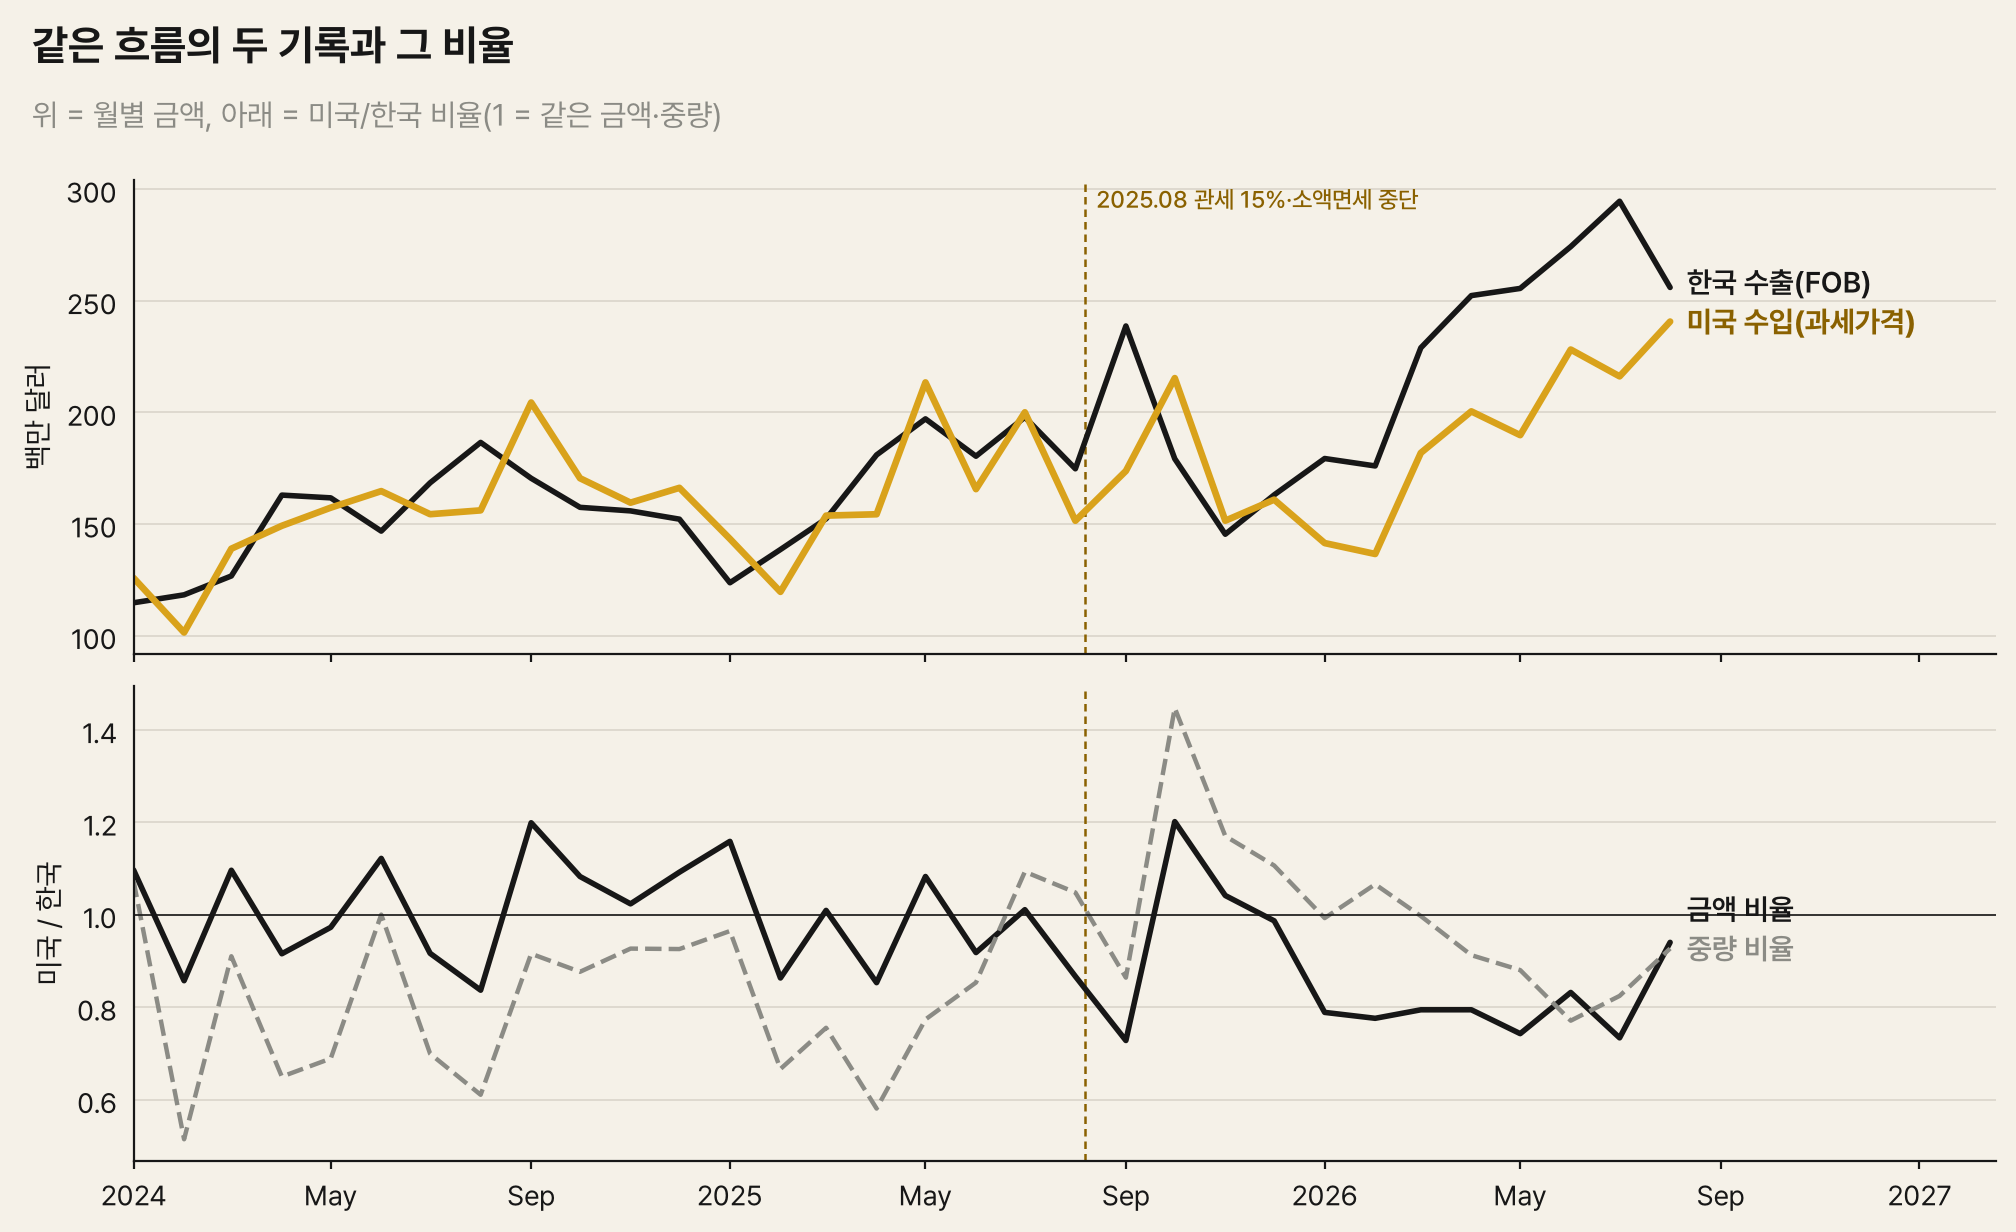

,kr_export_usd,us_import_usd,ratio_value,ratio_weight
month,,,,
2024-01-01,114.773,125.905,1.097,1.073
2024-02-01,118.332,101.452,0.857,0.514
2024-03-01,126.779,138.992,1.096,0.910
2024-04-01,162.997,149.252,0.916,0.650
2024-05-01,161.764,157.373,0.973,0.689
2024-06-01,146.873,164.788,1.122,1.000
2024-07-01,168.498,154.444,0.917,0.699
2024-08-01,186.591,156.158,0.837,0.611
2024-09-01,170.529,204.474,1.199,0.916


In [3]:
fig, axes = nbviz.figure((10, 6.6), 2, 1, title="같은 흐름의 두 기록과 그 비율", subtitle="위 = 월별 금액, 아래 = 미국/한국 비율(1 = 같은 금액·중량)", sharex=True)
axes[0].plot(m.index, m.kr_export_usd / 1e6, color=C["ink"], lw=2)
axes[0].plot(m.index, m.us_import_usd / 1e6, color=C["primary"], lw=2.4)
axes[0].set_ylabel("백만 달러")
axes[1].plot(m.index, m.ratio_value, color=C["ink"], lw=2)
axes[1].plot(m.index, m.ratio_weight, color=C["muted"], lw=1.6, ls="--")
axes[1].axhline(1, color=C["ink"], lw=0.6)
axes[1].set_ylabel("미국 / 한국")
for ax in axes:
    an.policy_marker(ax, label=ax is axes[0])
    ax.set_xlim(m.index.min(), m.index.max() + pd.Timedelta(days=200))
an.end_labels(axes[0], [(m.index[-1], m.kr_export_usd.iloc[-1] / 1e6, "한국 수출(FOB)", C["ink"], 600),
                        (m.index[-1], m.us_import_usd.iloc[-1] / 1e6, "미국 수입(과세가격)", C["primary_dark"], 700)])
an.end_labels(axes[1], [(m.index[-1], m.ratio_value.iloc[-1], "금액 비율", C["ink"], 600),
                        (m.index[-1], m.ratio_weight.iloc[-1], "중량 비율", C["muted"], 600)])
plt.show()
m[["kr_export_usd", "us_import_usd", "ratio_value", "ratio_weight"]].assign(
    kr_export_usd=lambda d: d.kr_export_usd / 1e6, us_import_usd=lambda d: d.us_import_usd / 1e6)

**발견**:
- 정책 전(2024-01~2025-08) 금액 비율은 0.84~1.20 사이를 오가며 평균 약 1이었다. 두 나라 기록이 크게 다르지 않았다.
- **2026년 1월부터 비율이 0.73~0.83에 머문다.** 한국 수출은 월 2.3~2.9억 달러로 급증했지만 미국 수입은 1.8~2.4억 달러에 그쳤다.
- 12개월 합계로 보면, 정책 후 한국은 대미 수출이 **+33.4%** 늘었다고 기록했지만 미국은 한국산 수입이 **+11.7%** 늘었다고 기록했다. 비율은 1.01 → 0.85.
- 중량 비율은 반대로 정책 전 0.5~1.1에서 정책 후 0.77~1.45로 올랐다.

측정 범위 가설이 맞다면 정책 후 **미국 쪽 기록이 상대적으로 늘어야** 한다. 원자료는 금액 기준으로 그 반대를 보여 준다.

## 3. 주 검정(사전 등록): 정책 후 미국/한국 비율이 올라갔나

In [4]:
tests = pd.DataFrame({
    "금액 비율": mirror.shift_test(m.log_ratio_value, BREAK),
    "중량 비율": mirror.shift_test(m.log_ratio_weight, BREAK),
}).T
tests[["pre_mean", "shift", "ci_low", "ci_high", "p_value", "pct_change_in_ratio", "placebo_p", "n_candidates", "largest_break"]]

,pre_mean,shift,ci_low,ci_high,p_value,pct_change_in_ratio,placebo_p,n_candidates,largest_break
금액 비율,-0.007,-0.152,-0.258,-0.045,0.005,-0.141,0.360,25,2026-01-01 00:00:00
중량 비율,-0.213,0.195,0.044,0.346,0.011,0.216,0.280,25,2025-07-01 00:00:00


**발견 (사전 등록 주 검정)**:

| 비율 | 정책 후 변화 | 95% CI | HAC p | 시간 위약 p (후보 25개) | 가장 큰 전환점 |
|---|---|---|---|---|---|
| 금액 (미국/한국) | **−0.152 (비율 −14%)** | −0.258 ~ −0.045 | 0.005 | 0.36 | 2026-01 |
| 중량 (미국 해상+항공/한국) | +0.195 (비율 +22%) | 0.044 ~ 0.346 | 0.011 | 0.28 | 2025-07 |

**판정**:
- 사전 등록 기준은 "정책 후 비율이 유의하게 상승하면 측정 범위 가설 지지"다.
- **금액 비율은 유의하게 떨어졌다. 예측과 반대 방향**이다.
- 중량 비율은 HAC 기준으로 유의하게 올랐다. 그러나 시간 위약에서 9월은 특별하지 않고(p 0.28), 가장 큰 전환점이 정책 **이전**인 2025년 7월이다.
- 두 비율이 반대로 움직인 이유는 4절의 상대 단가에서 드러난다.
- **종합하면 측정 범위 가설을 지지하는 근거는 없다.**

## 4. 반전: 같은 흐름, 반대 방향의 가격

금액 비율은 내리고 중량 비율은 올랐다. 그렇다면 같은 물량에 대해 **미국 측 kg당 금액이 한국 측보다 떨어졌다**는 뜻이다.
상대 단가 = (미국 금액 / 미국 해상+항공 중량) / (한국 FOB 금액 / 한국 중량) = 금액 비율 / 중량 비율.
보고서 그림 12는 정책 전후 12개월 합계(HS6 16개)로, 아래 월별 검정은 월 단위 비율로 같은 변화를 본다.

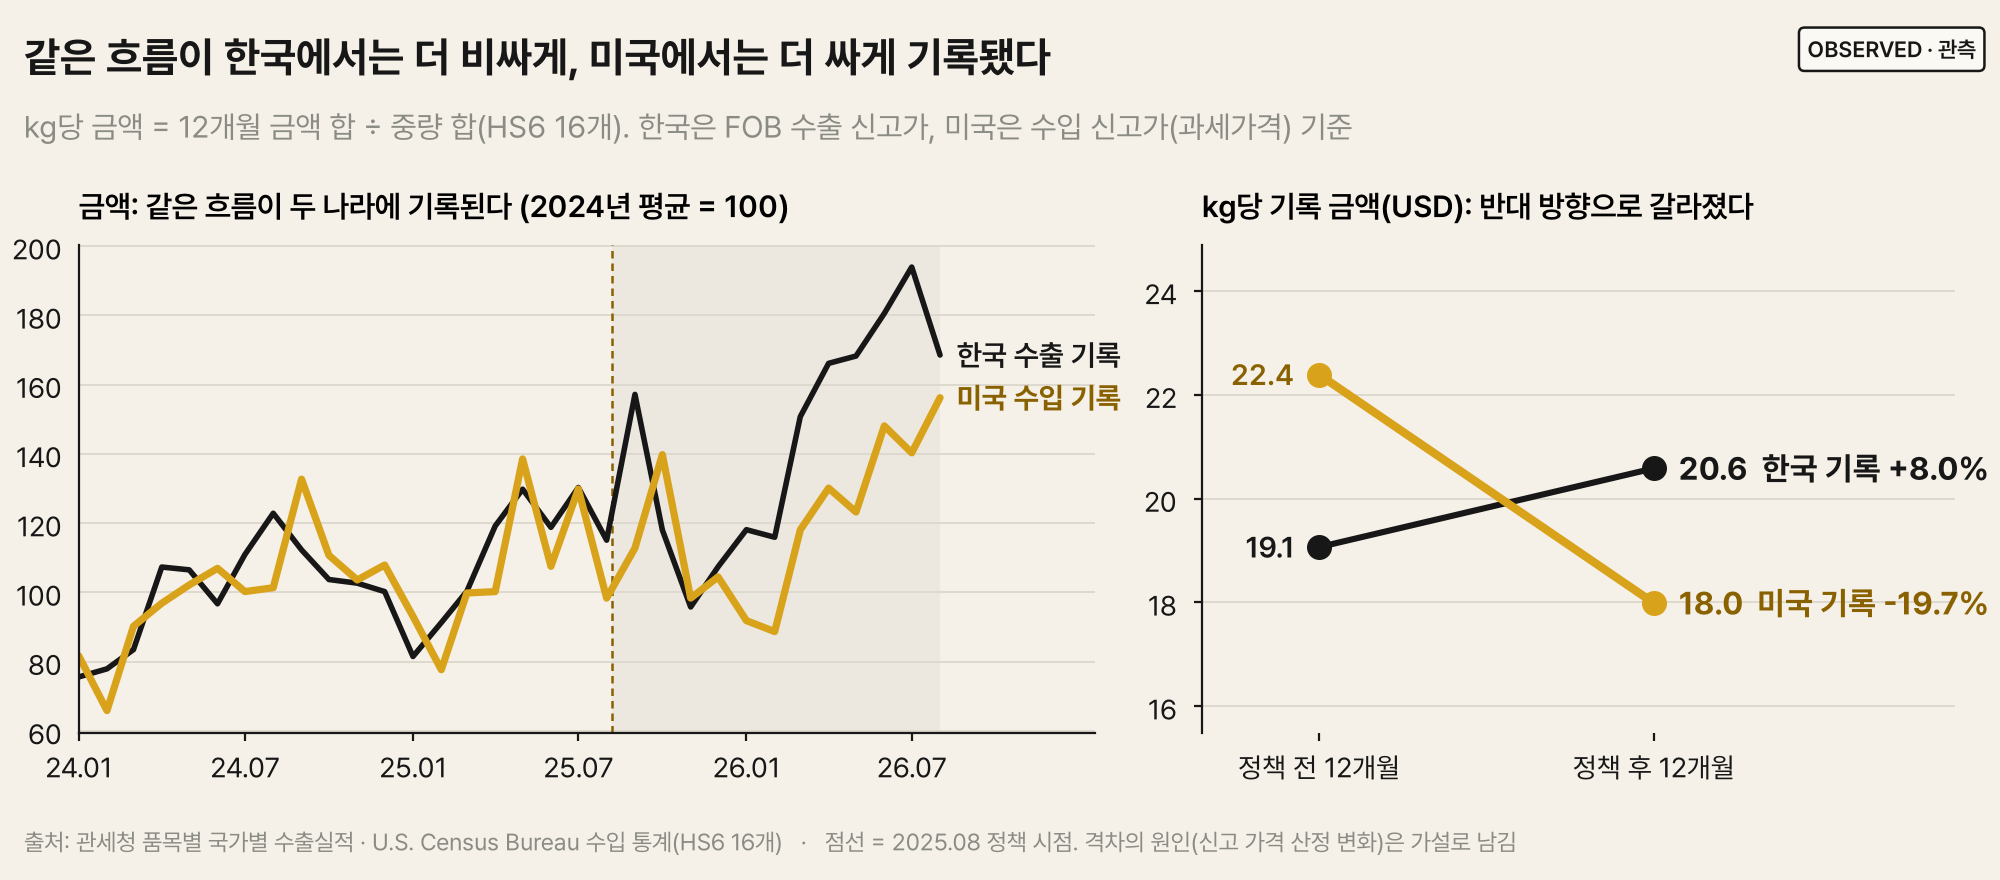

In [5]:
nbviz.show("12_mirror_same_flow_different_price")

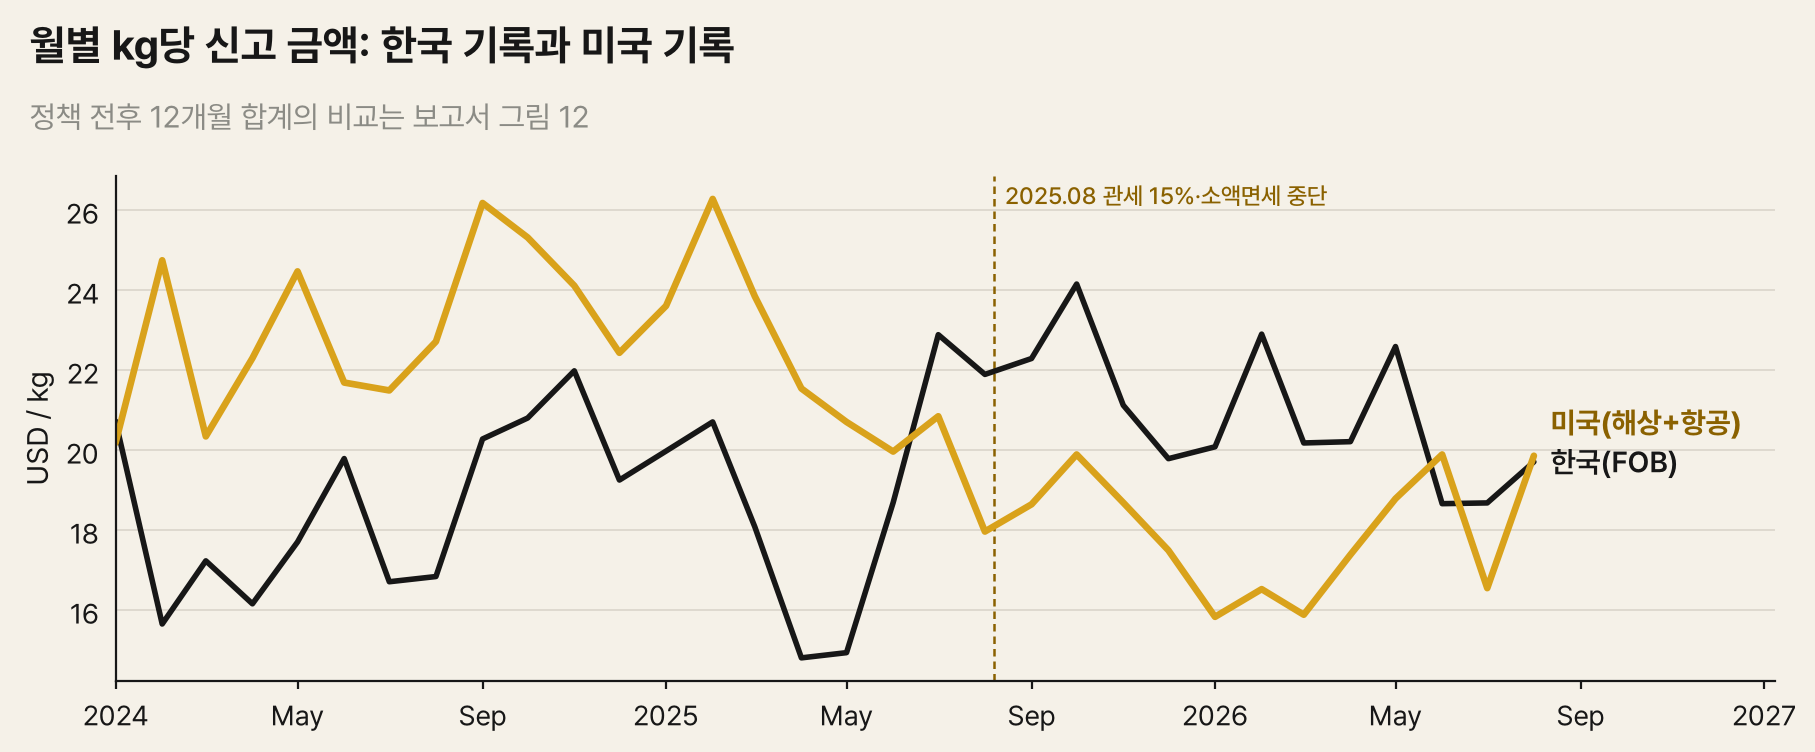

,pre_mean,shift,ci_low,ci_high,p_value,pct_change_in_ratio,placebo_p,largest_break
상대 단가 (미국/한국),0.187,-0.337,-0.442,-0.233,0.000,-0.286,0.160,2025-07-01 00:00:00
한국 USD/kg,2.924,0.112,0.039,0.184,0.003,0.118,0.360,2025-07-01 00:00:00
미국 USD/kg,3.111,-0.226,-0.310,-0.142,0.000,-0.202,0.280,2025-08-01 00:00:00


In [6]:
uv = pd.DataFrame({"kr_usd_per_kg": m.kr_export_usd / m.kr_export_kg,
                   "us_usd_per_kg": (m.us_vessel_usd + m.us_air_usd) / m.us_sea_air_kg})
uv["relative_us_over_kr"] = uv.us_usd_per_kg / uv.kr_usd_per_kg
fig, ax = nbviz.figure(title="월별 kg당 신고 금액: 한국 기록과 미국 기록", subtitle="정책 전후 12개월 합계의 비교는 보고서 그림 12")
ax.plot(uv.index, uv.kr_usd_per_kg, color=C["ink"], lw=2)
ax.plot(uv.index, uv.us_usd_per_kg, color=C["primary"], lw=2.4)
an.policy_marker(ax)
ax.set_ylabel("USD / kg")
ax.set_xlim(uv.index.min(), uv.index.max() + pd.Timedelta(days=160))
an.end_labels(ax, [(uv.index[-1], uv.kr_usd_per_kg.iloc[-1], "한국(FOB)", C["ink"], 600),
                   (uv.index[-1], uv.us_usd_per_kg.iloc[-1], "미국(해상+항공)", C["primary_dark"], 700)])
plt.show()
rel = pd.DataFrame({"상대 단가 (미국/한국)": mirror.shift_test(np.log(uv.relative_us_over_kr), BREAK),
                    "한국 USD/kg": mirror.shift_test(np.log(uv.kr_usd_per_kg), BREAK),
                    "미국 USD/kg": mirror.shift_test(np.log(uv.us_usd_per_kg), BREAK)}).T
rel[["pre_mean", "shift", "ci_low", "ci_high", "p_value", "pct_change_in_ratio", "placebo_p", "largest_break"]]

**발견**: 상대 단가(미국 kg당 금액 / 한국 kg당 금액)가 −0.337(−29%, p < 0.001) 떨어졌다.
한국 측 kg당 FOB 금액은 월별 검정에서 **+12%**(p 0.003) 올랐고, 미국 측 kg당 신고 금액은 **−20%**(p < 0.001) 떨어졌다.
12개월 합계로 보면 한국 +8.0%, 미국 −19.7%다(그림 12). 가장 큰 전환점은 2025년 7~8월로, 관세가 오른 시기와 겹친다(시간 위약 p 0.16).

금액 비율이 내려간 것은 미국 측 기록 물량이 한국보다 적어서가 아니라, **같은 물량을 미국 측이 더 낮은 가격으로 기록하기 시작했기** 때문이다.

## 5. 남는 해석과 확정할 수 없는 것

| 구분 | 내용 | 근거 수준 |
|---|---|---|
| 확인한 것 | 미국/한국 금액 비율 −14%, 소포 가설 지지 근거 없음 | `ESTIMATED` 사전 등록 주 검정 |
| 확인한 것 | kg당 기록 금액이 한국 측은 오르고 미국 측은 떨어짐 | `OBSERVED` 두 나라 통계 |
| 남는 해석 | 관세는 신고 가격에 비례해 붙는다. 관세가 오른 시기에 미국 측 신고 단가가 떨어진 것은 **과세가격 산정 방식의 변화**(예: 관계사 간 거래 가격, 최초 판매가 기준 신고)를 시사한다 | `INFERRED` |
| 확정할 수 없는 것 | 위 해석의 사실 여부. CBP 통관 단위 자료나 기업별 신고 자료가 있어야 검증할 수 있다 | `NOT MEASURED` |

03 노트북에서 항공 kg당 단가가 영국·프랑스·일본에서도 함께 떨어진 것과 같은 방향이다. 여러 나라에 공통된 '미국 측 신고 단가 하락'일 수 있다.

## 결론

| 질문 | 답 | 근거의 강도 |
|---|---|---|
| 정책 후 미국/한국 기록 비율이 올라갔나 (측정 범위 가설) | **아니다.** 금액 비율은 오히려 −14%(p 0.005). 미국 항공/한국 수출도 오르지 않음(p 0.15) | 강함: 시차·3개월 합계로 봐도 같은 결과. 다만 시간 위약 p 0.36 |
| 그럼 무엇이 달라졌나 | 같은 물량에 대해 **미국 측 kg당 신고 금액이 한국 측보다 29% 낮아짐**(한국 +12%, 미국 −20%) | 중간: 크기는 크고 유의하지만, 전환 시점이 9월로 특정되지 않고 7~8월 관세 인상 시기와 겹침(위약 p 0.16) |
| 외부 집계 14.5억 vs 미국 10.8억 | 품목 범위 0.8억 + **양국 통계 격차 2.9억** | 강함: 한국 측 원문에서 직접 재계산 |

### 이 결과가 바꾼 것
1. 처음에 "측정 범위 변화와 운송 방식 전환은 이 데이터로 구분할 수 없다"고 썼던 것을 고친다. 미러 분석은 **측정 범위 가설을 지지하지 않는다.**
2. 미국 측 기록만 보면 "물량은 늘고 kg당 단가는 떨어졌다"였다. 한국 측 기록으로 보면 **kg당 단가는 오히려 올랐다.** 단가 하락은 상품 자체보다 **미국 측 신고 가격의 변화**일 가능성이 크다.
3. 미국 통계로 K-뷰티 대미 수출 성장을 말하면 과소평가될 수 있다. 정책 후 12개월 성장률은 한국 기록 +33%, 미국 기록 +12%다.

### 한계
- 한국 수출 통계에는 운송수단 구분이 없어, 항공 소포만 따로 비교할 수 없다(분모가 전체 수출).
- 과세가격 산정 변화는 이 데이터로 검증할 수 없는 가설이다. 통관 단위 자료가 필요하다.
- 양국의 중량 정의(순중량·총중량)와 분류 관행이 다를 수 있어, 비율의 **수준**보다 **변화**만 해석했다.
- 보조 분석(부록 A2)과 4절의 상대 단가 검정은 사전 등록에 없던 분석이므로 판정이 아니라 해석을 돕는 용도로만 쓴다.

---

## 부록

본문 결론을 받치는 확인 작업이다. A2는 사전 등록에 없던 분석이라 판정이 아니라 해석을 돕는 용도로만 쓴다.

### A1. 시차

비율의 **수준**은 1이 아니어도 된다(가격 기준·시차·통관 범위가 다르다). 검정 대상은 비율의 **변화**다. 부산에서 월말에 출항한 화물은 다음 달 미국에 도착한다. 미국 월 t와 한국 월 t−k의 전월 대비 변화율 상관을 본다.

In [7]:
lag = mirror.lag_correlation(m.us_import_usd, m.kr_export_usd)
lag

,lag_months,corr,n
0,0,0.335,31
1,1,0.355,30
2,2,-0.113,29


**발견**: 전월 대비 변화율의 상관은 시차 0개월 0.34, 1개월 0.36, 2개월 −0.11이다. 시차 0과 1이 비슷하고, 상관 자체가 약하다(월별 기록은 잡음이 크다).
그래서 주 검정은 사전 등록대로 같은 달끼리 비교하고, A2에서 1개월 시차와 3개월 합계로도 확인한다.

### A2. 주 검정의 강건성(사전 등록에 없던 분석)

- 시차를 맞춘 비율: 미국 월 t / 한국 월 t−1
- 3개월 합계 비율: 월말 경계 효과를 줄인다
- 항공만 따로: 미국 항공 수입 / 한국 수출 (한국 통계에는 운송수단 구분이 없어 분모는 전체)
- 어느 HS6가 비율 변화를 만드나

In [8]:
aligned = np.log(m.us_import_usd / m.kr_export_usd.shift(1)).dropna()
rolling3 = np.log(m.us_import_usd.rolling(3).sum() / m.kr_export_usd.rolling(3).sum()).dropna()
air_only = np.log(m.us_air_usd / m.kr_export_usd)
vessel_only = np.log(m.us_vessel_usd / m.kr_export_usd)
aux = pd.DataFrame({
    "시차 맞춤 (미국 t / 한국 t−1)": mirror.shift_test(aligned, BREAK),
    "3개월 합계 비율": mirror.shift_test(rolling3, BREAK),
    "미국 항공 / 한국 전체": mirror.shift_test(air_only, BREAK),
    "미국 해상 / 한국 전체": mirror.shift_test(vessel_only, BREAK),
}).T
aux[["shift", "ci_low", "ci_high", "p_value", "pct_change_in_ratio", "placebo_p", "largest_break"]]

,shift,ci_low,ci_high,p_value,pct_change_in_ratio,placebo_p,largest_break
시차 맞춤 (미국 t / 한국 t−1),-0.137,-0.212,-0.061,0.000,-0.128,0.458,2026-05-01 00:00:00
3개월 합계 비율,-0.153,-0.248,-0.059,0.002,-0.142,0.304,2026-03-01 00:00:00
미국 항공 / 한국 전체,-0.090,-0.212,0.032,0.150,-0.086,0.640,2026-03-01 00:00:00
미국 해상 / 한국 전체,-0.155,-0.270,-0.040,0.008,-0.144,0.360,2026-01-01 00:00:00


In [9]:
gap = mirror.hs6_gap_change(mir_raw, PRE_WINDOW, POST_WINDOW)
gap.assign(**{c: gap[c] / 1e6 for c in ["kr_pre", "us_pre", "kr_post", "us_post", "gap_change_usd"]}).head(8)

,kr_pre,us_pre,ratio_pre,kr_post,us_post,ratio_post,gap_change_usd
hs6,,,,,,,
330499,"1,396.931","1,415.157",1.013,"1,934.045","1,627.555",0.842,-324.716
330790,207.595,78.792,0.380,285.715,92.302,0.323,-64.611
330410,180.499,242.295,1.342,164.977,210.861,1.278,-15.912
330590,71.257,69.622,0.977,98.238,85.991,0.875,-10.612
330420,50.009,112.727,2.254,54.751,121.166,2.213,3.697
330510,25.976,26.898,1.036,44.707,38.564,0.863,-7.065
330300,6.348,4.105,0.647,21.576,12.005,0.556,-7.328
330430,21.931,20.978,0.957,19.627,16.860,0.859,-1.814


**발견 (보조 분석, 사전 등록에 없음)**:
- **시차·경계 효과가 아니다**: 1개월 시차를 맞춰도 −0.137(p < 0.001), 3개월 합계로 봐도 −0.153(p 0.002). 금액 비율 하락은 그대로다.
- **가장 직접적인 검정, 미국 항공 / 한국 수출**: −0.090(95% CI −0.212~0.032, p 0.15). 소포가 미국 항공 통계에 새로 잡혔다면 이 비율이 올라야 하는데, 오르지 않았다.
- **해상**: 미국 해상 / 한국 수출은 −0.155(p 0.008)로 떨어졌다. 격차는 항공보다 해상에서 벌어졌다.
- **어느 품목에서**: 12개월 기준 '미국 − 한국' 격차가 4.27억 달러 벌어졌고, 그중 **3.25억 달러(76%)가 330499**에서 나왔다. 이 세목의 비율은 1.01 → 0.84.

### A3. 품목 범위와 외부 집계

이 분석은 HS 3303·3304·3305·3307만 쓴다. 비누(3401), 구강용품(3306), 향료 원료 등을 포함하면 한국 측 수출액이 얼마나 커지는지
보관된 관세청 원문에서 직접 계산한다(새 API 호출 없음). 아래 외부 집계 비교에 쓴다.

In [10]:
scopes = {
    "HS 3303·3304·3305·3307 (이 분석)": ("3303", "3304", "3305", "3307"),
    "+ 구강용품 3306": ("3303", "3304", "3305", "3306", "3307"),
    "HS 33 전체 (3301~3307)": ("33",),
    "HS 33 전체 + 비누 3401": ("33", "3401"),
}
raw_scope = {name: mirror.raw_exports(p) for name, p in scopes.items()}
h1_2026 = pd.Series({name: d[d.month.between("2026-01-01", "2026-06-01")].export_usd.sum() / 1e8
                     for name, d in raw_scope.items()}, name="2026 상반기 한국 → 미국 수출 (억 달러)")
h1_2026.to_frame()

,2026 상반기 한국 → 미국 수출 (억 달러)
HS 3303·3304·3305·3307 (이 분석),13.666
+ 구강용품 3306,13.683
HS 33 전체 (3301~3307),13.748
HS 33 전체 + 비누 3401,14.492


**발견**: 한국 측 수출을 품목 범위별로 다시 계산하면 2026년 상반기 대미 수출은 이 분석 범위(HS 3303·3304·3305·3307)에서 13.67억 달러,
HS 33 전체에서 13.75억 달러, **HS 33 전체 + 비누(3401)에서 14.49억 달러**다. 외부 집계 14.5억 달러와 거의 같다(아래 외부 집계 비교).

**외부 집계와의 차이: 14.5억 달러 vs 10.8억 달러**

프로젝트 기획 단계에서 인용한 "2026년 상반기 대미 화장품 수출 14.5억 달러(식약처)"와 이 분석의 미국 측 수입(같은 기간)을 나란히 놓고,
차이를 품목 범위 · 양국 통계 차이로 나눠 본다. 식약처 집계의 정확한 품목 정의는 원문을 확인하지 못했다.

In [11]:
h1 = m.loc["2026-01-01":"2026-06-01"]
bridge = pd.Series({
    "외부 집계 (식약처 인용, 품목 정의 미확인)": 14.5,
    "한국 수출: HS 33 전체 + 비누 3401": h1_2026["HS 33 전체 + 비누 3401"],
    "한국 수출: HS 33 전체": h1_2026["HS 33 전체 (3301~3307)"],
    "한국 수출: HS 3303·3304·3305·3307": h1.kr_export_usd.sum() / 1e8,
    "미국 수입: HS 3303·3304·3305·3307 (Census)": h1.us_import_usd.sum() / 1e8,
}, name="억 달러")
bridge.to_frame()

,억 달러
"외부 집계 (식약처 인용, 품목 정의 미확인)",14.500
한국 수출: HS 33 전체 + 비누 3401,14.492
한국 수출: HS 33 전체,13.748
한국 수출: HS 3303·3304·3305·3307,13.666
미국 수입: HS 3303·3304·3305·3307 (Census),10.786


**발견**: 외부 집계 14.5억 달러는 한국 관세청 기준 **HS 33 전체 + 비누(3401)의** 대미 수출(14.49억 달러)과 거의 같다. 외부 집계의 품목 정의를 이렇게 추정할 수 있다(원문 정의는 미확인).

같은 기간 미국 측 기록 10.79억 달러와의 차이 3.71억 달러는 두 부분으로 나뉜다.

| 구간 | 억 달러 | 설명 |
|---|---|---|
| 품목 범위 | 0.83 | 향료 원료(3301·3302), 구강용품(3306), 비누(3401)는 이 분석 범위 밖 |
| 양국 통계 차이 | **2.88** | 같은 4개 류에서 미국 기록이 한국 기록보다 21% 적음(10.79 / 13.67). 정책 전에는 거의 같았다(비율 1.01) |

즉 "14.5억 대 10.8억"의 차이 대부분은 품목 정의가 아니라 **정책 이후 벌어진 양국 통계의 격차**다.

### A4. 일치 확인

이 노트북의 주 검정 결과가 `scripts/run_all.py`가 만든 표(`reports/tables/mirror_shift.csv`)와 같은지 확인한다.

In [12]:
saved = pd.read_csv(TABLES_DIR / "mirror_shift.csv").set_index("metric")
assert np.isclose(saved.loc["log_ratio_value", "shift"], tests.loc["금액 비율", "shift"], atol=1e-12)
assert np.isclose(saved.loc["log_ratio_weight", "shift"], tests.loc["중량 비율", "shift"], atol=1e-12)
assert np.isclose(saved.loc["log_ratio_value", "placebo_p"], tests.loc["금액 비율", "placebo_p"], atol=1e-12)
print("notebook estimates match reports/tables/mirror_shift.csv")

notebook estimates match reports/tables/mirror_shift.csv
